In [112]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils


# --- Hyperparameters ---
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 128
NUM_FEATURES = 128
Z_DIM = 200
LEARNING_RATE = 0.0005
EPOCHS = 2
BETA = 2000

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [113]:
# Path to CelebA images
DATA_PATH = "img_align_celeba/img_align_celeba"

# Transforms: resize to 32x32 and normalize to [0,1]
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()  # values in [0,1]
])

# Dataset & DataLoader
train_dataset = datasets.ImageFolder(
    root=os.path.dirname(DATA_PATH),  # Folder containing subfolder "img_align_celeba"
    transform=transform
)

# NB: If you have a specific folder structure, adjust accordingly
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

In [114]:
print("Nombre d'images :", len(train_dataset))
print("Classes trouvées :", train_dataset.classes)

Nombre d'images : 202599
Classes trouvées : ['img_align_celeba']


torch.Size([128, 3, 32, 32])


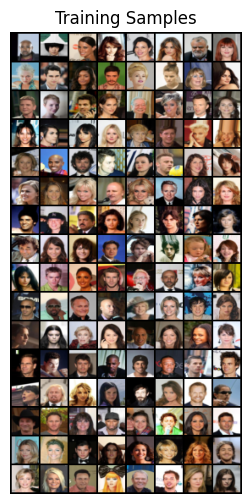

In [115]:
from torchvision import utils
import matplotlib.pyplot as plt

def show_batch(images, title=""):
    grid_img = utils.make_grid(images, nrow=8)
    plt.figure(figsize=(12, 6))
    plt.imshow(grid_img.permute(1, 2, 0).cpu().numpy())
    plt.title(title)
    plt.axis("off")
    plt.show()

data_iter = iter(train_loader)
images, _ = next(data_iter)

print(images.shape)
show_batch(images, title="Training Samples")

In [116]:
import torch
import torch.nn as nn

class Encoder(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.z_dim = z_dim

        self.net = nn.Sequential(
            nn.Conv2d(CHANNELS, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(NUM_FEATURES, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(NUM_FEATURES, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(NUM_FEATURES, NUM_FEATURES, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.flatten = nn.Flatten()

        fc_in_features = NUM_FEATURES * (IMAGE_SIZE // 2**4) ** 2

        self.mu = nn.Linear(fc_in_features, z_dim)
        self.logvar = nn.Linear(fc_in_features, z_dim)

    def forward(self, x):
        x = self.net(x)
        x = self.flatten(x)
        mu = self.mu(x)
        logvar = self.logvar(x)
        return mu, logvar

In [117]:
encoder = Encoder(z_dim=Z_DIM)
mu, logvar = encoder(images)

print("mu shape :", mu.shape)
print("logvar shape :", logvar.shape)

mu shape : torch.Size([128, 200])
logvar shape : torch.Size([128, 200])


In [118]:
class Sampling(nn.Module):
    def forward(self, mu, logvar):
        # Reparameterization trick
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

In [119]:
sampling = Sampling()
z = sampling(mu, logvar)

print("z shape :", z.shape)

z shape : torch.Size([128, 200])


In [120]:
class Decoder(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.z_dim = z_dim

        init_size = IMAGE_SIZE // 2**4   # 32 -> 2 après 4 réductions
        self.fc = nn.Linear(z_dim, NUM_FEATURES * init_size * init_size)

        self.unflatten = nn.Unflatten(1, (NUM_FEATURES, init_size, init_size))

        self.net = nn.Sequential(
            nn.ConvTranspose2d(NUM_FEATURES, NUM_FEATURES, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(NUM_FEATURES, NUM_FEATURES, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(NUM_FEATURES, NUM_FEATURES, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(NUM_FEATURES),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(NUM_FEATURES, CHANNELS, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.fc(z)
        x = self.unflatten(x)
        x = self.net(x)
        return x

In [121]:
decoder = Decoder(z_dim=Z_DIM)
recon_images = decoder(z)

print("recon_images shape :", recon_images.shape)

recon_images shape : torch.Size([128, 3, 32, 32])


In [122]:
class VAE(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.encoder = Encoder(z_dim)
        self.decoder = Decoder(z_dim)
        self.sampling = Sampling()

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.sampling(mu, logvar)
        recon = self.decoder(z)
        return mu, logvar, recon, z

In [123]:
vae = VAE(z_dim=Z_DIM)
mu, logvar, reconstructed, z = vae(images)

print("reconstructed shape :", reconstructed.shape)
print("mu shape :", mu.shape)
print("logvar shape :", logvar.shape)
print("z shape :", z.shape)

reconstructed shape : torch.Size([128, 3, 32, 32])
mu shape : torch.Size([128, 200])
logvar shape : torch.Size([128, 200])
z shape : torch.Size([128, 200])


In [124]:
def vae_loss_fn(x, recon, mu, logvar, beta=BETA):
    """
    x, recon: shape (N, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
    mu, logvar: shape (N, Z_DIM)
    """
    # 1) Reconstruction Loss
    recon_loss = F.mse_loss(recon, x, reduction="sum")

    # 2) KL Divergence
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - torch.exp(logvar))
    kl_loss = kl / x.size(0)

    total_loss = recon_loss + kl_loss * (beta / x.size(0))
    return total_loss, recon_loss, kl_loss

In [125]:
loss, recon_loss, kl_loss = vae_loss_fn(images, reconstructed, mu, logvar, BETA)

print("total loss :", loss.item())
print("recon loss :", recon_loss.item())
print("kl loss :", kl_loss.item())

total loss : 55311.0703125
recon loss : 54883.8203125
kl loss : 27.34400749206543


In [126]:
model = VAE(Z_DIM).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [127]:
for epoch in range(EPOCHS):
    model.train()
    total_loss_val = 0.0
    total_rec_val = 0.0
    total_kl_val = 0.0

    for batch_idx, (x, _) in enumerate(train_loader):
        x = x.to(DEVICE)

        optimizer.zero_grad()

        mu, logvar, recon, _ = model(x)
        loss, rec_loss, kl_loss = vae_loss_fn(x, recon, mu, logvar, BETA)

        loss.backward()
        optimizer.step()

        total_loss_val += loss.item()
        total_rec_val += rec_loss.item()
        total_kl_val += kl_loss.item()

    avg_loss = total_loss_val / len(train_loader)
    avg_rec = total_rec_val / len(train_loader)
    avg_kl = total_kl_val / len(train_loader)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | Loss: {avg_loss:.4f} | Recon: {avg_rec:.4f} | KL: {avg_kl:.4f}")

Epoch [1/2] | Loss: 6415.9111 | Recon: 5144.2433 | KL: 81.3867
Epoch [2/2] | Loss: 4521.2686 | Recon: 3241.6014 | KL: 81.8987


In [128]:
os.makedirs("./models", exist_ok=True)
torch.save(model.state_dict(), "./models/vae_face.pt")

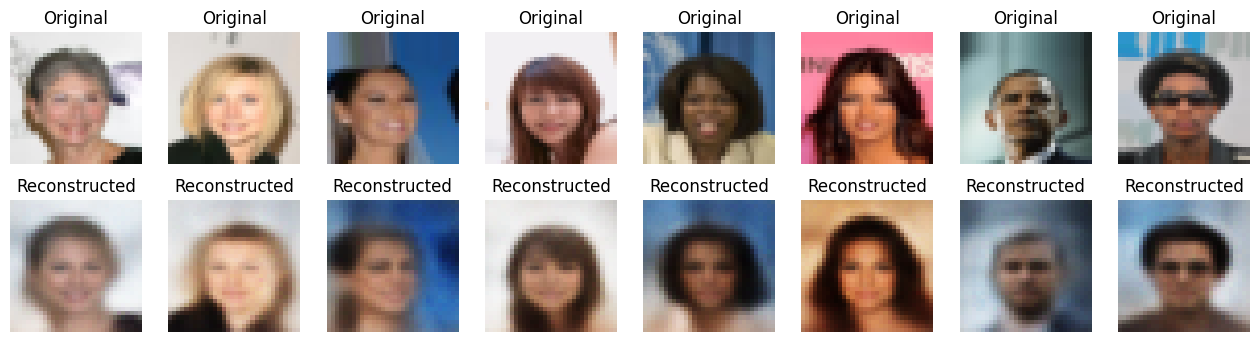

In [129]:
model.eval()

data_iter = iter(train_loader)
images, _ = next(data_iter)
images = images[:8].to(DEVICE)

with torch.no_grad():
    mu, logvar, recon, _ = model(images)

def show_reconstructions(orig, recon):
    n = orig.size(0)
    plt.figure(figsize=(2*n, 4))

    for i in range(n):
        plt.subplot(2, n, i + 1)
        plt.imshow(orig[i].permute(1, 2, 0).cpu().numpy())
        plt.title("Original")
        plt.axis("off")

    for i in range(n):
        plt.subplot(2, n, n + i + 1)
        plt.imshow(recon[i].permute(1, 2, 0).detach().cpu().numpy())
        plt.title("Reconstructed")
        plt.axis("off")

    plt.show()

show_reconstructions(images, recon)

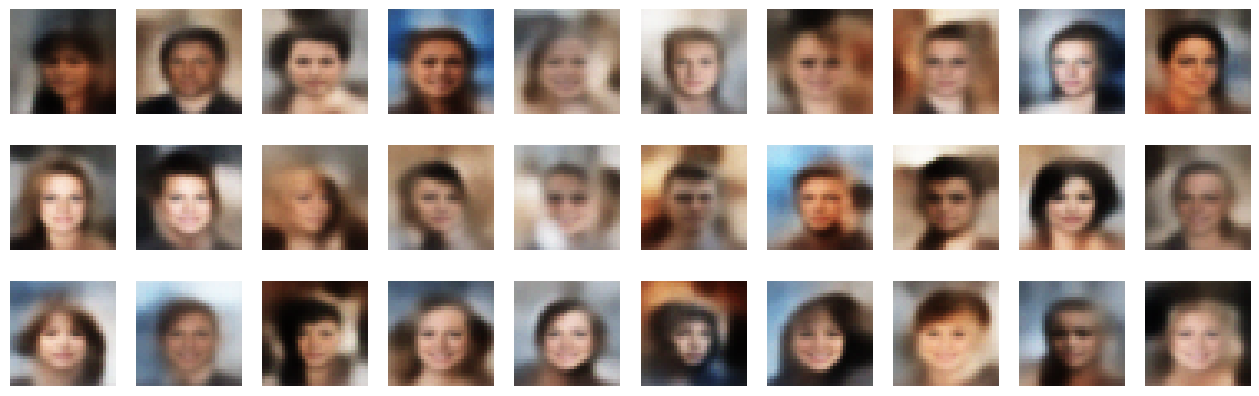

In [130]:
model.eval()

grid_width, grid_height = 10, 3
z_sample = torch.randn((grid_width * grid_height, Z_DIM)).to(DEVICE)

with torch.no_grad():
    recon = model.decoder(z_sample).detach()

def show_generated(recon, w=grid_width, h=grid_height):
    recon = recon.cpu()
    fig = plt.figure(figsize=(16, 5))

    for i in range(w * h):
        ax = fig.add_subplot(h, w, i + 1)
        ax.axis("off")
        ax.imshow(recon[i].permute(1, 2, 0).numpy())

    plt.show()

show_generated(recon)

In [132]:
import pandas as pd

# Load attributes
attributes = pd.read_csv("img_align_celeba/list_attr_celeba.csv")
print(attributes.columns)

LABEL = "Blond_Hair"  # or "Eyeglasses"

Index(['image_id', '5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive',
       'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose',
       'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows',
       'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair',
       'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open',
       'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin',
       'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns',
       'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings',
       'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace',
       'Wearing_Necktie', 'Young'],
      dtype='str')


In [133]:
from PIL import Image

class CelebADataset(torch.utils.data.Dataset):
    def __init__(self, img_folder, attr_csv, label=LABEL, transform=None):
        self.transform = transform
        self.img_folder = img_folder
        self.df = pd.read_csv(attr_csv)
        self.label = label

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        file_name = row["image_id"]
        path = os.path.join(self.img_folder, file_name)

        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label_val = row[self.label]

        # Convert -1 => 0, +1 => 1 if needed
        label_val = 0 if label_val == -1 else 1

        return image, label_val

In [134]:
label_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

img_folder = "img_align_celeba/img_align_celeba"

label_dataset = CelebADataset(
    img_folder,
    "img_align_celeba/list_attr_celeba.csv",
    label=LABEL,
    transform=label_transform
)

label_loader = DataLoader(
    label_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [135]:
images, labels = next(iter(label_loader))

print("images shape :", images.shape)
print("labels shape :", labels.shape)
print("labels sample :", labels[:10])

images shape : torch.Size([128, 3, 32, 32])
labels shape : torch.Size([128])
labels sample : tensor([0, 0, 1, 0, 0, 0, 0, 0, 0, 0])


In [ ]:
model.eval()

all_z = []
all_labels = []

with torch.no_grad():
    for images, labels in label_loader:
        images = images.to(DEVICE)

        mu, logvar, recon, z = model(images)

        all_z.append(z.cpu())
        all_labels.append(labels.cpu())

In [137]:
all_z = torch.cat(all_z, dim=0)
all_labels = torch.cat(all_labels, dim=0)

print("all_z shape :", all_z.shape)
print("all_labels shape :", all_labels.shape)

all_z shape : torch.Size([202599, 200])
all_labels shape : torch.Size([202599])


In [138]:
z_pos = all_z[all_labels == 1]
z_neg = all_z[all_labels == 0]

print("z_pos shape :", z_pos.shape)
print("z_neg shape :", z_neg.shape)

z_pos shape : torch.Size([29983, 200])
z_neg shape : torch.Size([172616, 200])


In [139]:
mean_pos = z_pos.mean(dim=0)
mean_neg = z_neg.mean(dim=0)

attribute_vector = mean_pos - mean_neg

print("attribute_vector shape :", attribute_vector.shape)

attribute_vector shape : torch.Size([200])


In [140]:
attribute_vector = attribute_vector / torch.norm(attribute_vector)
print("norme :", torch.norm(attribute_vector))

norme : tensor(1.0000)


In [141]:
model.eval()

test_images, test_labels = next(iter(label_loader))
test_image = test_images[0:1].to(DEVICE)

with torch.no_grad():
    mu, logvar = model.encoder(test_image)
    z = model.sampling(mu, logvar)

print("test_image shape :", test_image.shape)
print("z shape :", z.shape)

test_image shape : torch.Size([1, 3, 32, 32])
z shape : torch.Size([1, 200])


In [142]:
alpha = 2.0

attribute_vector_device = attribute_vector.to(DEVICE).unsqueeze(0)

z_plus = z + alpha * attribute_vector_device
z_minus = z - alpha * attribute_vector_device

In [143]:
with torch.no_grad():
    recon_original = model.decoder(z)
    recon_plus = model.decoder(z_plus)
    recon_minus = model.decoder(z_minus)

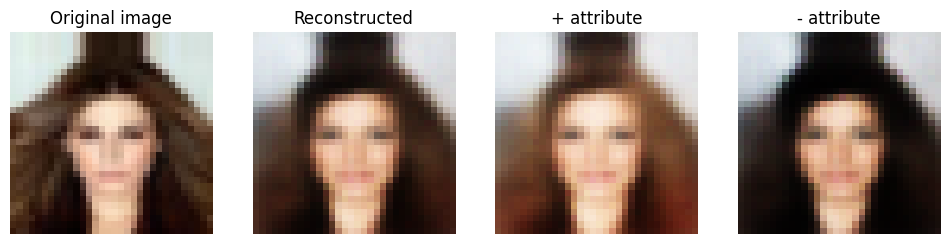

In [146]:
def show_attribute_edit(orig, rec_orig, rec_plus, rec_minus):
    plt.figure(figsize=(12, 3))

    titles = ["Original image", "Reconstructed", f"+ attribute", f"- attribute"]
    imgs = [orig[0], rec_orig[0], rec_plus[0], rec_minus[0]]

    for i, img in enumerate(imgs):
        plt.subplot(1, 4, i + 1)
        plt.imshow(img.permute(1, 2, 0).detach().cpu().numpy())
        plt.title(titles[i])
        plt.axis("off")

    plt.show()

show_attribute_edit(test_image.cpu(), recon_original, recon_plus, recon_minus)